## Walk vs. Run Classification (PRCP-1013)

Classify whether a person was walking or running from wrist-sensorsnapshots (accelerometer + gyroscope).

**Deliverables :** EDA report,model build, model comparison, challenges report — all in this notebook.

##### Safely Loading the DATA

In [1]:
import pandas as pd

df = pd.read_csv("../data/walkrun.csv", keep_default_na=False, na_values=[""])

print("Shape (rows, columns):", df.shape)
df.info()

Shape (rows, columns): (88588, 11)
<class 'pandas.DataFrame'>
RangeIndex: 88588 entries, 0 to 88587
Data columns (total 11 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   date            88588 non-null  str    
 1   time            88588 non-null  str    
 2   username        88588 non-null  str    
 3   wrist           88588 non-null  int64  
 4   activity        88588 non-null  int64  
 5   acceleration_x  88588 non-null  float64
 6   acceleration_y  88588 non-null  float64
 7   acceleration_z  88588 non-null  float64
 8   gyro_x          88588 non-null  float64
 9   gyro_y          88588 non-null  float64
 10  gyro_z          88588 non-null  float64
dtypes: float64(6), int64(2), str(3)
memory usage: 7.4 MB


##### Checking if data is similar to documentation

In [2]:
expected_cols = ["date", "time", "username", "wrist", "activity",
                 "acceleration_x", "acceleration_y", "acceleration_z",
                 "gyro_x", "gyro_y", "gyro_z"]

print("Columns in the file:", list(df.columns))
print()
print("In file but NOT in spec:", [c for c in df.columns if c not in expected_cols])
print("In spec but NOT in file:", [c for c in expected_cols if c not in df.columns])
print()
print("Missing values per column:")
print(df.isna().sum())
print()
print("Exact full-row duplicates:", df.duplicated().sum())

Columns in the file: ['date', 'time', 'username', 'wrist', 'activity', 'acceleration_x', 'acceleration_y', 'acceleration_z', 'gyro_x', 'gyro_y', 'gyro_z']

In file but NOT in spec: []
In spec but NOT in file: []

Missing values per column:
date              0
time              0
username          0
wrist             0
activity          0
acceleration_x    0
acceleration_y    0
acceleration_z    0
gyro_x            0
gyro_y            0
gyro_z            0
dtype: int64

Exact full-row duplicates: 0


In [3]:
print("Number of distinct users:", df["username"].nunique())
print()
print("Rows per user:")
print(df["username"].value_counts())

Number of distinct users: 1

Rows per user:
username
viktor    88588
Name: count, dtype: int64


##### Findings 1

1. | ROWS = 88,588 |
   COLUMNS = 11 |
   ALL COLUMN MATCH SPECS |
   0 MISSING |
   0 Extra duplicates |
   dtype matches |

2. Single User "viktor" across all rows

##### building a real timestamp to see the data span
- Both date and time are text object we need to convert them to a datetime object to understand the order and distance.

In [4]:
print(df[["date", "time"]].head(3))
print()

        date                time
0  2017-6-30  13:51:15:847724020
1  2017-6-30  13:51:16:246945023
2  2017-6-30  13:51:16:446233987



##### Findings 2
date and time are raw-logger format. the month is not padded with 0 and the time is counted in nanoseconds with a colon.

In [5]:
# the time column is "HH:MM:SS:NNNNNNNNN" -nanoseconds after a colon instead of a decimal point.
# the date has an unpaded month
# to make it a datetime we have to fix the strings then parse an explicit format.

# 1. Split time on ":" four columns: hour,minutes, second, nanoseconds
time_parts = df["time"].str.split(":", expand=True)
print(time_parts.head(3))
print()

# 2. Rebuild as a normal time string, keeping 6 of 9 nanoseconds digits
time_fixed = (time_parts[0] + ":" + time_parts[1] + ":" + time_parts[2] + "." + time_parts[3].str[:6])

# 3. Parse with an explicit format
df["timestamp"] = pd.to_datetime(df["date"] + " " + time_fixed, format ="%Y-%m-%d %H:%M:%S.%f")

print("Distinct dates:", df["date"].nunique())
print("Earliest:", df["timestamp"].min())
print("Latest:  ", df["timestamp"].max())
print()
print("Timestamps increase down the file (never go backwards):",
      df["timestamp"].is_monotonic_increasing)

    0   1   2          3
0  13  51  15  847724020
1  13  51  16  246945023
2  13  51  16  446233987

Distinct dates: 12
Earliest: 2017-06-30 13:51:15.847724
Latest:   2017-07-17 20:16:03.851119

Timestamps increase down the file (never go backwards): False


##### Findings 3
- the total date span is 18 days but only 12 days data exist the other 6 days data does not exist/missing.
- the rows are not chronological.

##### Checking the activity distribution by date
    A time-based split will only work nicely if both classes are in early and late part of timeline.
    if walking and running were recorded on seprate date. we need to reconsider how to split the data

In [6]:
# crosstab to create the frequency table 
activity_by_date = pd.crosstab(df["date"], df["activity"])
print(activity_by_date)

activity       0     1
date                  
2017-6-30   1241  2751
2017-7-1    2966  1235
2017-7-10   4337     0
2017-7-11      0  6696
2017-7-15    784  7150
2017-7-16  20480     0
2017-7-17   4554  6811
2017-7-2     429  3504
2017-7-4     324  2901
2017-7-6    4946  6411
2017-7-7    3280     0
2017-7-9     882  6906


##### Findings 4
- class 0 = 44223 vs class 1 = 44365  ~ 50% split
- some days only a single class was registred.
- on 2017-7-16 20480 rows of a single class are recorded which is = 23% of data

##### Understanding how the data is shuffled before sorting

In [7]:
# how is the data scrambled in this file
# 1. how many total times time run backwords as we go down the rows
backwards = df["timestamp"].diff() < pd.Timedelta(0)
print("Backwards jumps in file order:", backwards.sum())

# 2. is the file made of contiguous per-date blocks stitched out of
#    order, or rows shuffled at a fine scale?
blocks = (df["date"] != df["date"].shift()).sum()
print("Contiguous date blocks:", blocks, "| distinct dates:", df["date"].nunique())

Backwards jumps in file order: 9334
Contiguous date blocks: 12 | distinct dates: 12


##### Findings 5
- the rows are grouped by dates but the inside the groups the row order by time is a mess

##### Sorting into true time order

In [8]:
df = df.sort_values("timestamp").reset_index(drop=True)

print("Timestamps now increasing down the file:",
      df["timestamp"].is_monotonic_increasing)

Timestamps now increasing down the file: True


##### Understanding the time gap between the rows

In [9]:
# Real elpsed time between the neighbors
# small value = continuous session, big values = breaks between recording sessions.

gap_seconds = df["timestamp"].diff().dt.total_seconds()   
# .diff()Calculates the difference between each timestamp and the previous timestamp.
# .dt.total_seconds convert time into seconds

print("Most common gaps (seconds):")
print(gap_seconds.value_counts().head(10))
print()
print("Largest gap (seconds):", gap_seconds.max())

# A silence > 5 min clearly seprate sessions
# 5 minutes are DECLEARED threshhold, not  a discovered one.
session_breaks = gap_seconds > 300
print("Session breaks (silence > 5 min):", session_breaks.sum())
print("Recording sessions:", session_breaks.sum() + 1)

Most common gaps (seconds):
timestamp
0.200001    509
0.199997    423
0.199996    420
0.200000    386
0.200002    386
0.200005    375
0.200004    321
0.199998    299
0.200006    293
0.199992    292
Name: count, dtype: int64

Largest gap (seconds): 345242.187058
Session breaks (silence > 5 min): 18
Recording sessions: 19


##### Findings 6
- Most common gap is 0.20 seconds
- Largest gap is 345242 seconds = 4 days.
- total 18 times a session gap exceeded 5 mins.

##### No. of rows each day

In [10]:
df["date_real"] = df["timestamp"].dt.date

per_date = df.groupby("date_real")["timestamp"].agg(["count", "min", "max"])
print(per_date)

            count                        min                        max
date_real                                                              
2017-06-30   3992 2017-06-30 13:51:15.847724 2017-06-30 21:02:08.807271
2017-07-01   4201 2017-07-01 16:03:50.216769 2017-07-01 18:26:43.989657
2017-07-02   3933 2017-07-02 19:34:19.279332 2017-07-02 20:00:39.990742
2017-07-04   3225 2017-07-04 19:22:35.552372 2017-07-04 19:47:46.514648
2017-07-06  11357 2017-07-06 15:58:34.210725 2017-07-06 19:07:11.560231
2017-07-07   3280 2017-07-07 11:46:18.675924 2017-07-07 12:00:59.746272
2017-07-09   7788 2017-07-09 19:41:44.405398 2017-07-09 20:09:56.116228
2017-07-10   4337 2017-07-10 15:56:07.911439 2017-07-10 16:14:03.291770
2017-07-11   6696 2017-07-11 17:42:12.881653 2017-07-11 18:06:20.683199
2017-07-15   7934 2017-07-15 18:00:22.870257 2017-07-15 18:28:54.580790
2017-07-16  20480 2017-07-16 14:02:32.474889 2017-07-16 15:54:12.592303
2017-07-17  11365 2017-07-17 16:01:12.548662 2017-07-17 20:16:03

##### Findings 7

##### The dataset True shape

- 88,588 rows * 0.2 s ≈ 4.9 hours of actual recording
- it is covered over 19 different session across 12 days
- the 18 days timeline is only 5 hours of data collection.
- day windows lowest= 15 minutes and highest = 7.2 hours
- 2017-07-17 has total 38 minutes worth of data which is split in 40/60 across the classes.

### Pre-registered validation rule (Written before any model exist)

1. TEST = 2017-07-17  Cut: timestamp >= 2017-07-17 00:00:00.
   
   it is the latest date and the only date with healthy class balance (4554 vs 6811).

2. Train = Everything before this.

   The test data will be sealed. No EDA distributions, feature choices, tuning or model selection will touch it. (the above done class counts used to pick this day are split-design facts, not peeking.)

3. Embargo: The training period ends on July 16 at 15:54, and the test period begins on July 17 at 16:01, leaving a natural gap of approximately 24 hours. This separation reduces the risk of near-identical, temporally adjacent sensor readings appearing across the train/test boundary. The gap is naturally present in the data rather than artificially imposed.

4. Timestamp is created for splitting only- it is not considered a feature.
    since some days only have a single class present the model will try to relate that date with the output rather than movement pattern.

5. Test set will be evaluated only once at the end on final model.
    Accuracy alone doesnt provide enough info so we will use confusion matrix and per-class recall.

6. first we will define the training and validation folds and compare models using same folds and scoring rule. Only after that we will tune the promising model candidate.

   Fix the folds and scoring rule → compare baseline models fairly → tune promising candidates → choose the final model → evaluate the test set once.

7. Fit preprocessing separately within each fold. For example, a scaler must learn its means and standard deviations from that fold's training data, not from its validation data.

8. Since the data consist of 1 person across multiple day we will validate person across time.

   Your model is tested on the same person at a later time. It is not yet proven to work equally well for everyone.


Why each choice, briefly: an unthinking 80/20 time cut lands inside the giant all-one-class 07-16 block; including 07-16 in test makes it 79/21 lopsided; 07-17 alone is 40/60 and sealed by a ~24-hour natural embargo. Test share is 12.8% — smaller than convention, but statistically solid, and honest beats conventional. Train keeps 07-16's 20,480 single-class rows (26% of train, mild 51/49 skew — noted, not a problem).

##### Spliting the data

In [11]:
# one direction : past data will be used for traing, future for testing.
CUT = pd.Timestamp("2017-07-17 00:00:00")

train = df[df["timestamp"] < CUT].copy()
test = df[df["timestamp"] >= CUT].copy()

print("Train rows:", len(train), "| Test rows:", len(test))
print("Test share:", round(100 * len(test) / len(df), 1), "%")

Train rows: 77223 | Test rows: 11365
Test share: 12.8 %


##### Verifying the splits

In [12]:
print("Train classes (0 / 1):", train["activity"].value_counts().to_dict())
print("Test classes  (0 / 1):", test["activity"].value_counts().to_dict())
print()
print("Train span:", train["timestamp"].min(), "→", train["timestamp"].max())
print("Test span: ", test["timestamp"].min(), "→", test["timestamp"].max())
print()
embargo = (test["timestamp"].min() - train["timestamp"].max()).total_seconds()
print("Embargo:", round(embargo), "seconds ≈", round(embargo / 3600, 1), "hours")

Train classes (0 / 1): {0: 39669, 1: 37554}
Test classes  (0 / 1): {1: 6811, 0: 4554}

Train span: 2017-06-30 13:51:15.847724 → 2017-07-16 15:54:12.592303
Test span:  2017-07-17 16:01:12.548662 → 2017-07-17 20:16:03.851119

Embargo: 86820 seconds ≈ 24.1 hours


##### Split results

Train classes (0 / 1): {0: 39669, 1: 37554}

Test classes  (0 / 1): {1: 6811, 0: 4554}

Train span: 2017-06-30 13:51:15.847724 → 2017-07-16 15:54:12.592303

Test span:  2017-07-17 16:01:12.548662 → 2017-07-17 20:16:03.851119

Embargo: 86820 seconds ≈ 24.1 hours

### Task 1 EDA start

**Note :** EDA is on Train data only. 

##### 1. Column categorization.

| column | role | reason |
|---|---|---|
| date, time, timestamp | Only used for splitting the data | Since some day consist of a single class outcome, model may try to learn and associate that outcome directly to date insted of movement |
| username | **skip** | The whole dataset consist of a single users data. Not much info can be derived from this column |
| wrist | candidate feature(it acts as schedule leak so we refuse it) | check whether arm matters |
| activity | **target** | 0/1 — meaning about to be verified |
| acceleration_x/y/z, gyro_x/y/z | candidate features | the core physics |



##### Investigating and labeling output values (0 =? 1 =?)
    We know the two classes are walking and running, but we haven't been given a reliable mapping that tells us which label corresponds to which activity. So we'll use the sensor statistics to investigate.

The main idea is: running often produces stronger and faster movements than walking, so its sensor readings may show greater variability.

##### The mean and std for each feature seprately

In [13]:
# Per-axis stats by class. Read the stds and compare magnitudes —
# the mean of a raw axis mixes in gravity and arm orientation,
# so means are about posture; stds are about motion energy.
sensors = ["acceleration_x", "acceleration_y", "acceleration_z",
           "gyro_x", "gyro_y", "gyro_z"]

by_class = train.groupby("activity")[sensors].agg(["mean", "std"]).round(2)
print(by_class.T)   # transposed: classes side by side, per sensor

activity                0     1
acceleration_x mean -0.11  0.09
               std   0.33  1.33
acceleration_y mean -0.98 -0.19
               std   0.23  0.68
acceleration_z mean -0.23 -0.49
               std   0.12  0.68
gyro_x         mean -0.04  0.07
               std   1.10  1.27
gyro_y         mean  0.03  0.08
               std   1.07  1.32
gyro_z         mean  0.04 -0.00
               std   1.40  2.34


##### The mean and std for features combined

acceleration_x, acceleration_y, acceleration_z
Each measures the sensor signal along one direction. The values depend partly on how the sensor is oriented.

Combined magnitude = Combines the three axis values into one number, reducing dependence on the direction in which the signal points.

**Magnitude = square root of(x^2 + y^2 + z^2)**
    
    Total motion intensity regardless of which way the arm points. The cleaner physical signal.

In [14]:
import numpy as np

train["accel_mag"] = np.sqrt(train["acceleration_x"]**2 +
                              train["acceleration_y"]**2 +
                              train["acceleration_z"]**2)
train["gyro_mag"]  = np.sqrt(train["gyro_x"]**2 +
                              train["gyro_y"]**2 +
                              train["gyro_z"]**2)

print(train.groupby("activity")[["accel_mag", "gyro_mag"]]
           .agg(["mean", "std", "max"]).round(2))

         accel_mag             gyro_mag             
              mean   std   max     mean   std    max
activity                                            
0             1.07  0.23  2.18     1.88  0.89   6.61
1             1.45  0.94  5.74     2.73  1.17  11.78


**verdict** 

0 = walking

1 = Running

Class 1 shows larger motion energy on every sensor measure.(accel_mag mean 1.07 → 1.45, std 0.23 → 0.94,max 2.18 → 5.74).

A resting or gently-moving sensor still feels Earth's pull — 1 g.
walking accel_mag mean  = 1.07 ≈ 1.0. A tight cluster around 1.0 means the accelerometer reads in g-units, and gravity is the internal reference scale.

Walking's acceleration_y mean = −0.98. Gravity sitting almost entirely on the y-axis — an arm hanging at the side, y-axis pointing down. Running's y-mean is −0.19: arm bent and swinging, so gravity spreads across axes and motion adds in.

So the real comparison isn't "1.07 vs 1.45" in the abstract — it's gravity + small motion vs gravity + big motion, with run's max of 5.74 g marking impact spikes.

**Important:** This is a physics-based sanity check, not definitive proof of the labels. The exact pattern depends on how the sensor was worn and how the data was collected.

##### Findings 8
0 = walking    1 = Running

Class 1 shows larger motion energy on every sensor measure.(accel_mag mean 1.07 → 1.45, std 0.23 → 0.94,max 2.18 → 5.74).

Walk = gravity + small motion; run = gravity + bigmotion

Physics-based inference — strong,not absolute.

##### Visualizing Sensor Magnitudes by Activity

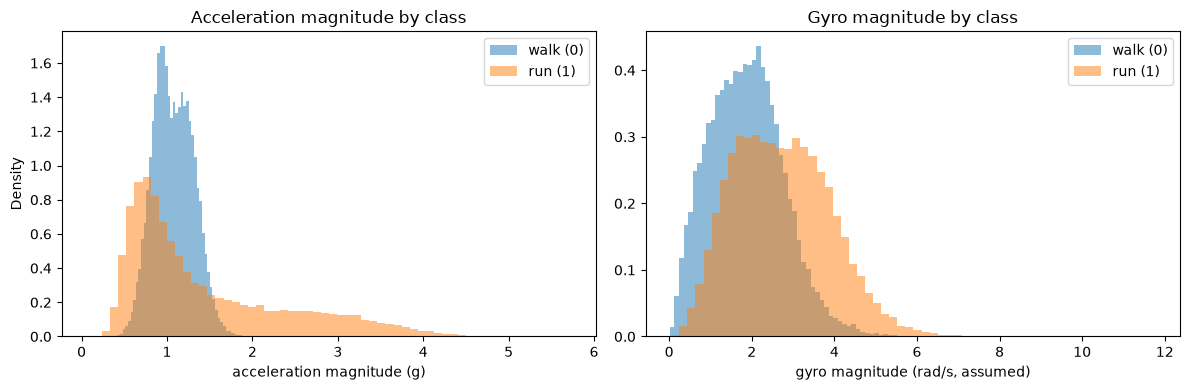

In [15]:
import matplotlib.pyplot as plt

walk = train[train["activity"] == 0]
run = train[train["activity"] == 1]

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.hist(walk["accel_mag"], bins=60, alpha=0.5, label="walk (0)", density=True)
plt.hist(run["accel_mag"], bins=60, alpha=0.5, label="run (1)", density=True)
plt.xlabel("acceleration magnitude (g)")
plt.ylabel("Density")
plt.title("Acceleration magnitude by class")
plt.legend()

plt.subplot(1, 2, 2)
plt.hist(walk["gyro_mag"], bins=60, alpha=0.5, label="walk (0)", density=True)
plt.hist(run["gyro_mag"], bins=60, alpha=0.5, label="run (1)", density=True)
plt.xlabel("gyro magnitude (rad/s, assumed)")
plt.title("Gyro magnitude by class")
plt.legend()

plt.tight_layout()
plt.show()

Acceleration magnitude-
    Both classes peaks near 1g. THey overlap near that area and are harder to distinguish. above 2.2g only running occurs.
    Run(1) has longer spread and tail than walk(0). so that area is distingushable.
    Magnitude alone cant properly seprate the classes any threshold misclassifies the overlap area. we will need extra information.
    
Gyro magnitude-
    Both are overlapping with run(1) has slightly more spread data than walk(0).

From both figures we can see the difference in each activitys magnitude.

In both figures activity 1 has more spread of data than activit 0.

##### Findings 9
Both classes peak near ~1g on accel_magnitude. Running adds a long tail. above ~2.2g only running occurs.

Magnitude alone cannot separate the classes.

#### Investigating wrist column

##### investigating Wrist–Activity Association and Sensor Orientation

In [16]:

print("Rows per wrist x class (train):")
print(pd.crosstab(train["wrist"], train["activity"]))
print()
print("P(running) within each wrist:")
print(pd.crosstab(train["wrist"], train["activity"], normalize="index").round(3))

Rows per wrist x class (train):
activity      0      1
wrist                 
0         14068  23708
1         25601  13846

P(running) within each wrist:
activity      0      1
wrist                 
0         0.372  0.628
1         0.649  0.351


1. Wrist and activity distribution

The crosstab shows that both wrists contain walking and running observations, so neither wrist is limited to a single activity. However, the activity proportions differ noticeably: wrist 0 contains 62.8% running observations, while wrist 1 contains 35.1%. Therefore, wrist is associated with activity in the training data and may provide predictive information. This association should be investigated carefully because it could reflect recording conditions rather than a general relationship.

2. Checking for a possible sensor-orientation effect

To investigate whether wrist placement affects sensor-axis readings, I compared the mean sensor values within the walking class only. Restricting the comparison to walkers helps reduce the possibility that differences arise simply from mixing walking and running observations.

In [17]:
print(walk.groupby("wrist")[sensors].mean().round(2))

       acceleration_x  acceleration_y  acceleration_z  gyro_x  gyro_y  gyro_z
wrist                                                                        
0                0.30           -1.00           -0.21   -0.06    0.02    0.06
1               -0.33           -0.97           -0.24   -0.03    0.03    0.02


Left and right arms are mirror images. the axis running across the body flips the sign between them.( x: +0.30 vs -0.33). while gravity stays on hanging y -axis(-1.00-- vs -0.97, nearly identical).

Conclusion: Wrist may contain useful information about both activity distribution and sensor-axis patterns. I will retain it as a candidate feature and compare models with and without it using the same time-based validation folds before making the final decision.

##### Investigating Wrist Usage Patterns

- Check whether the wrist changed multiple times within a day or remained the same throughout the day's recordings.
- Understand whether wrist usage is associated with particular recording days or sessions.
- Identify whether the model might learn a recording-specific pattern instead of a reliable relationship between sensor readings and activity.
- This helps assess whether the wrist feature could mislead the model if wrist usage patterns change in future recordings.

In [18]:
# which wrist was worn on which day?
print(pd.crosstab(train["date_real"], train["wrist"]))

wrist           0      1
date_real               
2017-06-30   3992      0
2017-07-01   4201      0
2017-07-02   3933      0
2017-07-04   3225      0
2017-07-06  11357      0
2017-07-07   3280      0
2017-07-09   7788      0
2017-07-10      0   4337
2017-07-11      0   6696
2017-07-15      0   7934
2017-07-16      0  20480


Each recording day contains only one wrist in the training data.

Wrist 0 appears on earlier 8(06-30 to 07-09) recording days, while wrist 1 appears on the later 4 (07-10 to 07-16)recorded days shown here.zero mixing

Means the 62.8 % / 35.1 % of running activity split is depending on time period not on arm basis.
wrist = almost calender 
since wrist can provide schedule info it will mislead the model

###### since we are traing model on forward chaining fold validating days 2-9 training is 100% wrist 0 a constant column nothing to learn, and it later folds : training through 07-10 teaches "wrist 1 → walk" (07-10 is 4,337 walk, 0 run)… and the very next validation day, 07-11, is 6,696 run, 0 walk. The shortcut flips sign day to day. The ablation would measure chaos.

**Conclusion** = "wrist" column excluded from model training

##### Findings 10
Wrist 0 appears on earlier 8(06-30 to 07-09) recording days, while wrist 1 appears on the later 4 (07-10 to 07-16)recorded days shown here.zero mixing.

Means the 62.8 % / 35.1 % of running activity split is depending on time period not on arm basis. wrist = almost calender since wrist can provide schedule info it will mislead the model

**Conclusion** = "wrist" column excluded from model training

#### Investigating if a random train-test split would give a realistic estimate of future performance

##### Do neighboring rows have same label?
##### Are neighboring sensor values almost identical?

In [19]:
assert train["timestamp"].is_monotonic_increasing

# How often do consecutive (time-sorted) rows share same label
same_label = (train["activity"] == train["activity"].shift()).mean()
print("Consecutive rows with same label:", round(100 * same_label, 2), "%")

# How similar are neighbors in sesonr space vs random pairs?
neighbor_diff = train["accel_mag"].diff().abs()
rng = np.random.default_rng(seed=42)
i = rng.integers(0, len(train), len(neighbor_diff))
j = rng.integers(0, len(train), len(neighbor_diff))
random_diff = np.abs(train["accel_mag"].to_numpy()[i] -
                     train["accel_mag"].to_numpy()[j])
print("Mean |Δ accel_mag| — time neighbors:", round(neighbor_diff.mean(), 3))
print("Mean |Δ accel_mag| — random pairs:  ", round(random_diff.mean(), 3))
print("Ratio (random / neighbors):",
      round(random_diff.mean() / neighbor_diff.mean(), 1))

Consecutive rows with same label: 99.98 %
Mean |Δ accel_mag| — time neighbors: 0.709
Mean |Δ accel_mag| — random pairs:   0.675
Ratio (random / neighbors): 1.0


##### the transition analysis

In [20]:
# where do labels change
transition = train["activity"].ne(train["activity"].shift())
gaps = train["timestamp"].diff().dt.total_seconds()

changes = pd.DataFrame({
    "timestamp": train.loc[transitions, "timestamp"],
    "from": train["activity"].shift().loc[transitions],
    "to": train["activity"].loc[transitions],
    "gap_s": gaps.loc[transitions],
}).dropna()

print(changes.to_string(index=False))
print()
print("Label blocks in train:", len(changes) + 1)
print("smallest silence before a label change:", round(changes["gap_s"].min(), 1), "s")

# Which activity drives the high neighbor-churn? Split the neighbor
# diffs by activity (~all pairs share the label, so current row works).
nb = train["accel_mag"].diff().abs()
print(train.assign(nb=nb).groupby("activity")["nb"].mean().round(3))

NameError: name 'transitions' is not defined

1. Consecutive rows with same label: 99.98 % 
    Almost every row has same activity label as preceding row.indicates strong label continuity in time-sorted data

2. Acceleration magnitude does not show much differance in neighboring rows vs rows selected randomly (0.709 for neighbors vs 0.675 for random pairs.).Neighbors were not more similar by this measurement.

3. There are 15 label blocks in train and 14 times the actual activity label changes in time sorted data.Each label change follows a gap of at least 8.2 seconds, rather than an ordinary 0.2-second interval.

   labels remain the same across neighboring rows, but sensor values can change substantially.

4. Activity 0: sensor readings change by an average of 0.300.
- Activity 1: sensor readings change by an average of 1.141.
- Activity 1 has much bigger changes between consecutive readings

**Conclusion**: 
    A random split can place rows from the same recording sessions or activity blocks in both training and testing sets. This may produce an overly optimistic evaluation because the model is tested on recording conditions it has already encountered. Model may check which session does this rading comes from instead of sensor reading.

##### time-based split will obtain a more realistic estimate of performance on future recordings.

##### Findings 11
Consecutive rows with same label: 99.98 % Almost every row has same activity label as preceding row.indicates strong label continuity in time-sorted data

There are 15 label blocks in train and 14 times the actual activity label changes in time sorted data.Each label change follows a gap of at least 8.2 seconds, rather than an ordinary 0.2-second interval.

##### Findings 12
Acceleration magnitude does not show much differance in neighboring rows vs rows selected randomly (0.709 for neighbors vs 0.675 for random pairs.).Neighbors were not more similar by this measurement.

labels remain the same across neighboring rows, but sensor values can change substantially.

##### Findings 13
- Activity 0: sensor readings change by an average of 0.300.
- Activity 1: sensor readings change by an average of 1.141.
- Activity 1 has much bigger changes between consecutive readings
- Running's fast oscillation and impact spikes drive value churn; explainsF12.

##### Findings 14
Effective independent units ≈ 15 label blocks(19 sessions), not 77,223 rows. Random splits violate independence at block level → temporal split with natural ~24 h embargo is the honest design. Test = 07-17 (11,365 rows, 40/60 classes), sealed until the single final evaluation.

In [ ]:
##### Checking Co-relation in features

In [ ]:
# checking correlation in features
corr_cols = sensors + ["accel_mag", "gyro_mag"]
print(train[corr_cols].corr().round(2))

##### No strong co-relation observed in different features

##### Findings 15
No strong co-relation observed in different features (|r| ≥ 0.7).

Notable moderate pairs: accel_mag ↔acceleration_z = −0.65, acceleration_x ↔ acceleration_z = −0.57,accel_mag ↔ gyro_mag = 0.44.

Inference : walk rows are near-constants(no variance to correlate), run spikes dive on z; magnitudes rise with intensity together. All six axes retained.

### TASK 1 - EDA REPORT

# TASK 1 — Exploratory Data Analysis (EDA) Report

## 1. Dataset Overview

The dataset contains sensor recordings from a single user, Viktor, performing walking and running activities across multiple recording sessions.

- **Dataset size:** 88,588 rows × 11 columns
- **Recording start:** 2017-06-30 13:51:15.847724
- **Recording end:** 2017-07-17 20:16:03.851119
- **Calendar span:** 18 days, from June 30 to July 17
- **Active recording days:** 12 days
- **Recording sessions:** 19 sessions, using a gap of more than 5 minutes to define a new session

Each row represents a sensor reading recorded at a particular point in time.

Although the dataset spans 18 calendar days, recordings exist on only 12 of those days. The data therefore represents separate recording periods rather than continuous monitoring throughout the entire date range.

All 88,588 rows belong to a single user; the dataset therefore supports within-person validation only

## 2. Class Distribution and Recording Patterns

The target variable contains two activity classes:

| Activity label | Number of rows | Percentage |
|---|---:|---:|
| 0 — Walking | 44,223 | 49.92% |
| 1 — Running | 44,365 | 50.08% |

The overall class distribution is almost perfectly balanced. However, the recordings are not necessarily balanced across individual days or sessions.

Key observations:

- Some recording days contain only one activity class.
- On July 16, 20,480 rows belong to a single class, representing approximately 23.1% of the entire dataset.
- July 17 contains 11,365 rows, with an approximately 40/60 class distribution.
- Recording durations vary substantially between days, from approximately 15 minutes to 7.2 hours of recorded time within a day.

**Interpretation:** Overall class balance does not guarantee balanced representation across recording days. A model could learn patterns associated with particular recording periods instead of learning activity-related sensor patterns alone.

## 3. Timeline, Recording Gaps and Sessions

The most common interval between consecutive readings is approximately 0.20 seconds, equivalent to around five readings per second during regular recording.

However, the timeline contains substantial gaps:

- **Largest gap:** 345,242 seconds, approximately 4 days.
- **Session gaps:** 18 gaps exceeded 5 minutes, resulting in 19 sessions.
- **Estimated recording duration:** 88,588 readings at a nominal interval of 0.20 seconds correspond to approximately 4.9 hours of sampling time on full data.

The 4.9-hour figure is an estimate based on the typical sampling interval, not an exact measure of recorded duration on full data. Actual elapsed time includes long gaps between sessions.

**Interpretation:** The dataset contains short periods of sensor recording distributed across a much longer calendar timeline. Rows must therefore be analysed in chronological order, with recording gaps and session boundaries taken into account.

## 4. Temporal Dependence and Potential Data Leakage

After sorting the data chronologically, approximately 99.98% of consecutive rows share the same activity label.

This indicates strong label continuity: the activity label usually remains unchanged between neighbouring readings.

A separate comparison examined the absolute difference in acceleration magnitude between consecutive readings and between randomly selected pairs:

| Comparison | Mean absolute difference |
|---|---:|
| Consecutive time neighbours | 0.709 |
| Randomly selected pairs | 0.675 |

The differences are similar. Therefore, this particular comparison does not demonstrate that neighbouring acceleration-magnitude values are nearly identical to one another.

However, strong label continuity still matters for validation. A random row-level split could place readings from the same activity blocks or recording sessions in both the training and test sets. This may produce an overly optimistic estimate of performance on genuinely later recordings.

The dataset contains approximately 15 label-continuous blocks, despite having 77,000-plus consecutive row comparisons. the 15 label blocks are nested inside the 19 sessions — every one of the 14 label changes followed a silence ≥ 8.2 s, .label changes occur only across recording silences.


**Validation decision:** Use a chronological training/validation strategy rather than a random row-level split. Keep July 17 as the final test day, separated from the training period by the natural overnight gap of approximately 24 hours. Do not use the test set for model selection or tuning; evaluate it once after the modelling decisions are finalised.

we assumed near-twin values, measured, found ratio 1.0, and corrected the leakage mechanism accordingly.


## 5. Sensor Behaviour and Activity-Label Verification

The activity labels are interpreted as follows:

- **Class 0:** Walking
- **Class 1:** Running

This mapping is supported by the observed sensor patterns and physical expectations, but it has not been independently confirmed from external label documentation.

### Acceleration magnitude

The acceleration magnitude combines the three accelerometer axes into one measure of the overall acceleration vector:

The observed statistics were:

| Statistic | Walking (0) | Running (1) |
|---|---:|---:|
| Mean acceleration magnitude | 1.07 | 1.45 |
| Standard deviation | 0.23 | 0.94 |
| Maximum | 2.18 | 5.74 |

Class 1 has a higher average magnitude, substantially greater variation and a higher maximum value.

Both classes peak around 1g, but running shows a longer upper tail. In this dataset, values above approximately 2.2g occur only in class 1.

run churns 1.141 per neighbor vs walk's 0.300 

**Interpretation:** These observations are consistent with walking producing relatively steady sensor readings and running producing stronger, more variable movement. However, acceleration magnitude alone is unlikely to separate the two activities perfectly because their distributions overlap.

The same general pattern of greater motion variation in class 1 should also be checked across the gyroscope measurements before finalising the label interpretation.

### Limitations of physics-based inference

The class mapping is inferred from sensor behaviour rather than independently verified ground-truth documentation. Sensor units and orientation assumptions should also be confirmed where possible. These limitations should be considered when interpreting model results.

## 6. Wrist Analysis and Recording-Time Confounding

The dataset contains readings from two wrist categories, represented by 0 and 1.

The wrist distribution is closely associated with the recording date:

- Wrist 0 appears on the earlier recording days, from June 30 to July 9.
- Wrist 1 appears on the later recording days, from July 10 to July 16.
- Each observed recording day contains only one wrist category.

The activity proportions also differ between wrist categories. The percentage of class 1 readings is approximately 62.8% for wrist 0 and 35.1% for wrist 1.

**Interpretation:** Wrist category is strongly confounded with recording date. Since the wrist changes between the earlier and later recording periods, the observed class-distribution difference cannot be attributed to the wrist itself independently of time.

A model could use wrist as a shortcut to identify recording periods and their associated activity distributions. This could reduce its ability to generalise to future recordings where the relationship between wrist and activity differs.

The sensor-axis patterns may also vary with wrist orientation. For example, the mean x-axis acceleration differs in sign between the two wrist categories (approximately +0.30 versus −0.33), while the y-axis means are similar (approximately −1.00 versus −0.97). These differences may reflect sensor orientation or arm positioning rather than activity alone.

**Feature-selection decision:** Exclude the wrist column from the primary model because it is confounded with recording time.

## 7. Feature Selection Plan

### Features excluded from the primary model

- **Username:** Identifies the individual rather than a general activity pattern.
- **Date and time:** May allow the model to exploit recording schedules instead of movement.
- **Timestamp:** Used for chronological sorting and splitting, not as a model input.
- **Wrist:** Strongly associated with the recording period and therefore potentially misleading.

### Features included in the primary model

- `acceleration_x`, `acceleration_y`, `acceleration_z`
- `gyro_x`, `gyro_y`, `gyro_z`

Acceleration and gyroscope magnitudes may be evaluated as an additional feature variant. They should be compared against the baseline using the same time-based validation folds.

No pair of the six axes reaches the redundancy threshold of |r| ≥ 0.7 (largest: acceleration_x–acceleration_z at −0.57).

No feature should be removed or retained solely because a simple correlation analysis shows a weak relationship. Correlation measures only certain types of association and may not capture the usefulness of a feature for classification.so all six axes are retained."

## 8. Limitations

1. **Single user:** The results assess generalisation across time for Viktor, not generalisation across different people.
2. **Limited recording days:** Recordings span 12 active days and 19 sessions, with uneven class distributions across dates.
3. **Single final test day:** July 17 provides a limited estimate of performance on future recordings.
4. **Inferred activity labels:** The mapping of class 0 to walking and class 1 to running is based on observed sensor behaviour and physical expectations.
5. **Sensor assumptions:** Sensor units, calibration and orientation are assumed to be consistent unless independently verified.
6. **Temporal dependence:** Consecutive rows are strongly label-continuous, so row-level random splitting could overestimate real-world performance.

## 9. Overall Conclusion

The dataset is almost perfectly balanced at the overall class level, but its recordings are unevenly distributed across dates and sessions. Strong temporal label continuity makes random row-level validation unsuitable for estimating performance on future recordings.

Sensor statistics support the interpretation that class 1 represents running and class 0 represents walking, although this mapping remains an inference. Wrist category is strongly associated with recording time, making it a potential source of shortcut learning.

The primary modelling approach will therefore use the six raw accelerometer and gyroscope axes, exclude identifying and time-related columns, and use chronological validation with July 17 reserved for one final evaluation. Magnitude features may be tested as an alternative, while results will be reported with the limitation that they represent within-person, across-time performance rather than across-person generalisation.

## Task 2

### Step 1 . Pre - Register the evaluation protocol

##### Fold design - Chronological. Forward Chaining by day.

11 Training days, chronological.

Fold i = we train on all previous day before day i and validate on day i.

Validation will always be on the future of training data.

First validation is on 3rd day. training on 1 day data can be less informative.

##### Scoring Rule
Per fold : recall_walk, recall_run (None where a class is absent.)

Aggregates: accuracy mean per fold ± std over 9 folds

| recall_walk mean (over its 8 folds) | recall_run mean (over its 6 folds) |

Primary Metric: Balanced mean recall = average of two mean recalls.

fold 9 alone holds 20,480 all walk rows.Accuracy alone could therefore favour a model that performs poorly on one activity. Balanced mean recall reduces this risk by giving equal weight to the average recall of each activity class.

##### Decision rules:

1. Ladder order is fixed:
       We will run every model regardless of previous models result. also negative results will be documented.
   Dummy -> LogReg -> RandomForest -> MLP
2. A new model advances only if its balanced mean recall improves on the current best model by at least 1 percentage point (0.01 on a 0-1 scale).

    If the improvement is smaller than 0.01, or the scores are tied, the simpler model is preferred. Additional complexity must provide a meaningful improvement to justify its use.

3. To qualify as a final candidate the model must achieve both Mean walking recall and mean running recall values ≥ 0.95. A model that fails either threshold does not pass the predefined performance gate, even if its overall balanced mean recall is high.
4. Only the selected winner from the initial model ladder is tuned. Hyperparameter- tuning are documented before tuning begins to reduce the risk of making decision on observed results.
5. Every model uses a pipeline containing StandardScaler() followed by the classifier. The scaler is fitted only on the training portion of each fold and then applied to that fold's validation data. this prevents validation data from influencing the scaling parameters.
    - random_state=42 is used wherever applicable.
    - Rows are kept in chronological order; they are never shuffled.
    - The same predefined time-based validation folds are used for all models.
6. Magnitude-Feature Comparison

    After completing the initial model ladder, magnitude-feature variants are evaluated using the same validation folds. This allows a fair comparison between the raw sensor axes and the additional magnitude features without changing the validation data.

Overall Principle

The goal is to select a model that identifies both activities reliably, generalises to later recordings, and avoids unnecessary complexity. Model selection, tuning and feature comparisons follow predefined rules rather than whichever approach produces the most attractive result.

##### Why Day-Level Folds Instead of TimeSeriesSplit

TimeSeriesSplit divide data at row boundaries. Depending on where a split falls, the training set may contain morning readings while the validation set contains afternoon recording from the same day.

This recordings may share recording conditions, sensor mounting and other day-specific characteristics. the model could therefore perform well on validation data that is very similar to what it has already seen during training.

This is the risk validation strategy is designed to reduce.

Decision: Use day-level folds where complete recording days are kept together rather than splitting a day between training and validation. training uses earlier days, while validation uses a later day.

This better tests whether the model generalise to recordings from a different day instead of merely predicting more readings from a familier recording period.

### Creating Harness

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, recall_score

FEATURES = ["acceleration_x", "acceleration_y", "acceleration_z",
            "gyro_x", "gyro_y", "gyro_z"]

#generating the folds
days = sorted(train["date_real"].unique())

def run_ladder(pipeline, model_name):
    """Run any pipeline through the 9 pre registered day-level folds. Return the pre-fold table.
    """
    rows = []

    for i in range(2, len(days)):         # we start the first validation on 3rd day since day1 and day2 would have insufficient data
        train_days = days[:i]             # all days before i
        val_day = days[i]                 # day i = validation future day

        part = train[train["date_real"].isin(train_days)]
        val = train[train["date_real"] == val_day]

        pipeline.fit(part[FEATURES], part["activity"])         # x features y output of training
        pred = pipeline.predict(val[FEATURES])                 # validation day X features

        rows.append({
            "model": model_name,
            "val_day": str(val_day),
            "n_rows": len(val),
            "accuracy": accuracy_score(val["activity"], pred),     # y real on y pred on validation day
            "recall_walk": recall_score(val["activity"], pred, pos_label=0)
                        if (val["activity"] == 0).any() else None,     # only check if at least 1 walking row exist
            "recall_run": recall_score(val["activity"], pred, pos_label=1)
                        if (val["activity"]== 1).any() else None,      # only check if at least 1 running row exist
        })

    return pd.DataFrame(rows)


def summarize(df_folds, model_name):
    """The pre-registered aggregates for one model's fold table."""
    acc = df_folds["accuracy"]
    rw = df_folds["recall_walk"].dropna()
    rr = df_folds["recall_run"].dropna()
    print(f"===={model_name}===")
    print("Accuracy: mean", round(acc.mean(), 3), "±", round(acc.std(), 3))
    print("Mean recall_walk:", round(rw.mean(), 3), f"({len(rw)}/9 folds)")
    print("Mean recall_run:", round(rr.mean(), 3), f"({len(rr)}/9 fold)")
    print("Balanced mean recall:", round((rw.mean() + rr.mean()) / 2, 3))     

### Dummy Model

We create a Dummy model to establish a baseline — a minimum level of performance that more useful models should try to beat.

Before building a model that learns from sensor data, we ask:
“How well can we do without learning any movement patterns at all?”

It looks at the activity labels in the training data and always predicts whichever class occurs most frequently.

In [ ]:
from sklearn.dummy import DummyClassifier

dummy_pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("clf", DummyClassifier(strategy="most_frequent")),
])

dummy_folds = run_ladder(dummy_pipe, "Dummy")
print(dummy_folds.round(3))
summarize(dummy_folds, "Dummy")
    

The model achieved a mean accuracy of 0.485 ± 0.451 and a balanced mean recall of 0.479 
.Mean walking recall was only 0.125, compared to the 0.833 for running.

The large variation in accuracy across folds reflects the changing activity distribution across recording days. In particular, the model achieved zero accuracy on several walking-only days because it predicted running for every sample.

These results establish a weak baseline and demonstrate why accuracy alone is insufficient for this dataset. Balanced mean recall will be the primary metric for comparing subsequent models.

##### Every real model must beat Balanced mean recall 0.479 by ≥ 0.01 to advance.

### Logistic Regression
It is one of the simplest model which learns from features.
if a straigh boundry seprates walking from running we want to know it, and by exactly how much.

It sees each row in isolation. it cannot comute variance, rythm or how a reading is related to its neighbors. it only knows where a row sits. its error therefore must come from EDA overlap zone: runnings quiet moments that look like walking.

In [ ]:
from sklearn.linear_model import LogisticRegression

logreg_pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("clf", LogisticRegression(max_iter=1000, random_state=42)),
])
logreg_folds = run_ladder(logreg_pipe, "LogReg")
print(logreg_folds.round(3))
summarize(logreg_folds, "LogReg")

Logistic regression produced Balanced mean recall of 0.82.it was right for guessing walk with mean recall_walk = 0.838 andfor running mean recall_run = 0.803.

It substancially outperformed dummy model.It predicted walking slightly better than running.But its performanced varid across validation days(0.644 to 0.904).
On the running-only days of july 11 and walking only days of july 16 it performed far worse than other days.

On 07-16 it performed accuracy of 0.71 that is 5,920 out of 20,480 rows were misclassified as running.the single largest error mass in whole evalution.

##### Every next model must beat Balanced mean recall 0.82 by ≥ 0.01 to advance.

#### Corficients of the final fold's model
- the coefficient of final folds model are saved as weights from them we can interpret which feature the model thinks as the most important to predict outcome correctly

In [ ]:
# The coefficients of the final fold's model, read as feature importance.
# Fit on ALL of train once: this is interpretation, not evaluation.
from sklearn.linear_model import LogisticRegression

explainer = Pipeline([
    ("scaler", StandardScaler()),
    ("clf", LogisticRegression(max_iter=1000, random_state=42)),
])
explainer.fit(train[FEATURES], train["activity"])

coefs = pd.Series(explainer[-1].coef_[0], index=FEATURES).sort_values()
print(coefs.round(3))

From above we see acceleration_y feature (4.329) is the most important feature to correctly guess the output.We assumed that y axis points downward as a resting position with gravity acting on it.gravity makes walk's y negative and pinned; running makes it rise.

acceleration_x feature showed the lowest importance in three accelerating features But it still gives (0.653) enough data to model than gyro features .accerelation_x feature value changes as external factors changes like changing wrist.( +0.30 vs -0.33 from findings f10).the model may have factored it in its learning.

features related to gyro have much lower importance than feature related to acceleration in predicting the output.It might be because gyros information substancially overlaps acceleration info. making it redundant signals.

### RandomForest
Random Forest can learn nonlinear relationships between features by repeatedly splitting data using thresholds.

For example, if one feature alone cannot distinguish walking from running accurately, a tree can check another feature as well. The prediction can depend on a combination of conditions across multiple features. This allows it to learn complex relationships and feature interactions.

A Random Forest builds multiple decision trees. Each tree learns its own splits and makes a prediction. The trees vote, and the class receiving the most votes becomes the final prediction.

Difference from Logistic Regression: Logistic Regression combines all features using learned coefficients to calculate a prediction. Random Forest uses threshold-based rules, where the importance of one feature can depend on the values of other features. This helps it learn nonlinear patterns and interactions.

Limitation: Each row is still evaluated independently using its available feature values. The model does not automatically consider the row's position in time or the neighboring sensor readings. Therefore, it does not directly learn movement rhythm or patterns across consecutive readings.

In [ ]:
from sklearn.ensemble import RandomForestClassifier

rf_pipe = Pipeline([
    ("scaler", StandardScaler()),      # Random Forest generally does not need scaling but keeping i here is harmless and consistant
    ("clf", RandomForestClassifier(n_estimators=200, random_state=42)),
])
rf_folds = run_ladder(rf_pipe, "RandomForest")
print(rf_folds.round(3))
summarize(rf_folds, "RandomForest")

RandomForest produced Balanced mean recall of 0.924.it was right for guessing walk with mean recall_walk = 0.865 and for running mean recall_run = 0.983.

It predicted running(0.983) more accurately than walking(0.865).

It has abnormal accuracy (0.178) on 07-10 which was walk-only day.fold 6 trains on days 06-30→07-09 — all wrist-0, the model never saw a wrist-1 row in its life. The wrist changes on 07-10, the validation day itself.the model met the opposite orientation convention for the first time, with no wrist-1 rows in training to adapt from.then fold 7+ (with wrist-1 days entering training) the scores jump back to 0.96–0.99. The model recovered the moment wrist-1 rows entered training. Adaptation data, not permanent damage.

Stability: mixed-day spread 0.975–0.992 — tighter than LogReg's 0.805–0.904. Robustness confirmed. The ± 0.267 std is fold 6 alone inflating it — without that fold, RF's std would be tiny; the aggregate "0.89 ± 0.267" is honest but the explanation is "one bad fold," not "unstable model."

##### Every next model must beat Balanced mean recall 0.924 by ≥ 0.01 to advance.

### Multi-Layer Perceptron (MLP)
MLP learns combination of features through multiple layers, allowing it to disover complex pattern that logistic regression might miss.
it passes learned combination through multiple layers of neurons and non-linear activations like ReLU.it adjusts weights using gradients while randomForest builds decision trees.
More flexibility does not guarantee better performance.

MLP also treat each row in isolation.without taking info from its neighbors and position.

In [ ]:
from sklearn.neural_network import MLPClassifier

mlp_pipe = Pipeline([
    ("scaler", StandardScaler()),         # scaling matters for MLP
    ("clf", MLPClassifier(hidden_layer_sizes=(64, 32), max_iter=500, random_state=42)),
])
mlp_folds = run_ladder(mlp_pipe, "MLP")
print(mlp_folds.round(3))
summarize(mlp_folds, "MLP")

MLP produced Balanced mean recall of 0.924.it was right for guessing walk with mean recall_walk = 0.872 and for running mean recall_run = 0.976.

It predicted running(0.976) more accurately than walking(0.872).

It performed exceptionally well on every day except for 07-10 which was the first day wrist changed data was introduced (0.108) worse than RandomForest(0.178) on same day.
It picked up on next day when it learned from the new data.
If we exclude day 07-10 it performed with an accuracy of 0.978. that day is dragging the performance down.

the aggregate "0.881 ± 0.291" is honest but the explanation is "one bad fold," not "unstable model."

##### Verdict : 
RandomForest and MLP both produced a model with Balanced mean Recall of 0.924 so it is a tie.

To qualify as a final candidate the model must achieve both Mean walking recall and mean running recall values ≥ 0.95. A model that fails either threshold does not pass the predefined performance gate, even if its overall balanced mean recall is high.

With our pre described protocol both models fails the criterion.

**Trigger:** ladder complete; gate FAILED (walk recalls 0.865/0.872 < 0.95).Protocol requires an improvement attempt before the sealed test opens.

### Using windows instead of rows -
    From the data there is possibility that model relying on individual raw readings learns patterns that dont transfer well to a different recording condition(change of wrist, orientation change). 

    five-second summaries may reveal more reliable movement characteristics than individual readings, especially when individual sensor values are noisy or affected by orientation.

what is windows = instead of feeding the model a single row data at a time we will make a window and group multiple rows together then calculate the features mean, std, lowest value, highest value, of this grouped row and create a new single row of in this case 6 * 4 = 24 features .

#### Windows specification (declared, not tuned)

1. Length : 25 rows approx. 5 seconds at interval of 0.2 seconds each.
   this gives model severral seconds of movement data instead of single instant.
2. Build windows only within continuous runs of data, splitting whenever the gap between consecutive rows exceed 1 second. all 14 observed label changes occur silences of at least 8.2 seconds. therefore window should not cross these observed label changes. verifing this withan assertion code rather than relying on the assumption
3. stride - setiing window stride equal to its length (25 rows) producing non overlapping windows. this avoids creating highly similar overlapping windows that could make validation results overly optimistic.
4. tail rows - Drop any leftover rows that do not complete a window length of 25 rows. count and repot the dropped rows.
5. Label - Assign each window its shared activity label. Asser that every window contains only one label


#### Features
For each of the 6 sensor channels, calculate the mean, standard deviation (std), minimum (min), and maximum (max), giving 24 features per window.

#### Validation 
Compare Logistic regression and random forest using the same 9 chronological folds, scoring metrics and decision rules used for row based models. pay particular attention to the difficult july 10  validation fold. Recheck the model selection gate before tuning the winner.if exactly one passes → it's the champion, light tuning pass; if both pass → they compete by rule 2 on the same folds; if neither passes → we document the gate failure 

**keep the july 17 final test day untouched until model selection is complete**

#### Window construction

In [ ]:
WINDOW = 25     # ROWS PER WINDOW APPROX 5 SECONDS AT 0.2 INTERVALS
GAP_S = 1.0     # nay inter row silence > 1s start a new run

# train is time-sorted . diff() gives the gap to the previous row
# so run id increment exactly at each > 1s silence
gap = train["timestamp"].diff().dt.total_seconds()
train = train.assign(run_id=(gap > GAP_S).cumsum())       # cumulative sum

# Building windows inside each run, non- overlapping(stride = length)
rows = []
for run_id, run in train.groupby("run_id"):
    if len(run) < WINDOW:
        continue
    for start in range(0, len(run) - WINDOW + 1, WINDOW):
        w = run.iloc[start:start + WINDOW]
        rows.append({
        "run_id": run_id,
        "date_real": w["date_real"].iloc[0],
        "activity": w["activity"].mode().iloc[0],
        })

windows = pd.DataFrame(rows)
print("Windows built:", len(windows))
print("Labels:", windows["activity"].value_counts().to_dict())


# === the purity assert: a window rows share one label ===
# mode() picks the majority; assert it is UNANIMOUS, not merely dominant
for run_id, run in train.groupby("run_id"):
    if len(run) >= WINDOW:
        for start in range(0, len(run) - WINDOW + 1, WINDOW):
            w = run.iloc[start:start + WINDOW]
            assert w["activity"].nunique() == 1, f"mixed-label window in run {run_id}"

assert (gap > GAP_S).sum() == train["run_id"].max()          # runs = breaks + 1
print("Purity assert passed: every window single-label; run segmentation verified.")

Total of 3016 windows were built from the training data. of which walking consist of 1556 windows and running of 1460 windows.

every single window consisted of a single output label

##### Dropped rows

In [ ]:
used = len(windows) * WINDOW
dropped = len(train) - used
print("Rows in windows:", used, "| rows in NO window:", dropped,
      f"({100 * dropped / len(train):.1f}% of train)")
print("Runs (>1s segmentation):", int(train["run_id"].max()) + 1)

##### appending features

In [ ]:
#====== the 24 features, per window =============

def window_features(w):
    feats = {}
    for c in FEATURES:
        feats[f"{c}_mean"] = w[c].mean()
        feats[f"{c}_std"] = w[c].std()
        feats[f"{c}_min"] = w[c].min()
        feats[f"{c}_max"] = w[c].max()
    return feats

X_all = []
for run_id, run in train.groupby("run_id"):
    if len(run) < WINDOW:
        continue
    for start in range(0, len(run) - WINDOW + 1, WINDOW):
        X_all.append(window_features(run.iloc[start:start + WINDOW]))

X_windows = pd.DataFrame(X_all)
y_windows = windows["activity"]
print("Feature matrix:", X_windows.shape, "| expected (n_windows, 24)")

##### Building harness

In [ ]:
#====same folds, smae rules -windows inherit the harness ===
# one desing point: our previous ladder harness keys on train rows. for windows we
# keep the identical 9 folds by validating on windows whose DATE is the fold's val day
# the folds design is unchanged the unit is.

def run_window_ladder(pipeline, model_name):
    rows_out = []
    for i in range(2, len(days)):
        val_day = days[i]
        tr_mask = ~windows["date_real"].isin(days[:i]) & windows["date_real"].isin(days)
        # train = windows from days before the val_day (val_day excluded)
        tr = windows[windows["date_real"].isin(days[:i])]
        va = windows[windows["date_real"] == val_day]
        Xtr, ytr = X_windows.loc[tr.index], y_windows.loc[tr.index]
        Xva, yva = X_windows.loc[va.index], y_windows.loc[va.index]

        pipeline.fit(Xtr, ytr)
        pred = pipeline.predict(Xva)

        rows_out.append({
            "model": model_name,
            "val_day": str(val_day),
            "n_windows": len(va),
            "accuracy": accuracy_score(yva, pred),
            "recall_walk": recall_score(yva, pred, pos_label=0)
                        if (yva == 0).any() else None,
            "recall_run": recall_score(yva, pred, pos_label=1)
                        if (yva ==1).any() else None,
        })
    return pd.DataFrame(rows_out)

#### Logistic Regression using windows

In [ ]:
win_logreg_folds = run_window_ladder(
    Pipeline([("scaler", StandardScaler()),
              ("clf", LogisticRegression(max_iter=1000, random_state=42))]), "Window LogReg")
print(win_logreg_folds.round(3))
summarize(win_logreg_folds, "Window LogReg")

Logistic regression using windows produced Balanced mean recall of 0.993.it was right for guessing walk with mean recall_walk = 1.0 and for running mean recall_run = 0.986.

On day 07-10 when first time the model was introduced to change of wrist data it performed with accuracy of 1.0 on the next day when that data was used in training it dropped to 0.917.

The model performed substantilly well after using windows.

##### This result already surpassed all previous model and at the edge 0.993. we will compare this value with next model to determine the final candidate based on our predescibed rules.

#### RandomForest using Windows

In [ ]:
win_rf_folds = run_window_ladder(
    Pipeline([("scaler", StandardScaler()),
              ("clf", RandomForestClassifier(n_estimators=200, random_state=42))]), "Window RF")
print(win_rf_folds.round(3))
summarize(win_rf_folds, "Window RF")

RandomForest using windows produced Balanced mean recall of 0.999.it was right for guessing walk with mean recall_walk = 0.999 and for running mean recall_run = 0.999.

On day 07-10 when first time the model was introduced to change of wrist data it performed with accuracy of 0.994 indicating this model adapts well to change in external circumstances.

The model performed substantilly well after using windows.

#### Verdict:

After using windows the balanced mean recall is

**Logistic Regression = 0.993**

**RandomForest = 0.999**

With our criteria of change > 0.01 both the models are tied. No significant difference.

The RandomForest model performed better when new changes were introduced in the data compared to Logistic Regression.

As Per our self described rules when models are tied we go for simplicity and easier deployment conditions. so the logistic regression edge out comapared to RandomForest.

**Final candidate: Logistic Regression using windows**

it satisfy the condition of

| mean_recall_walk > 0.95 with value of 1.0 | mean_recall_run > 0.95 with value of 0.986| 



### Tuning the final model - Logistic Regression with windows

The final selected models cross-validated error is 22 windows out of 3016(balanced mean recall of 0.993).Even after tuning run eliminating every error would gain 0.007 which is less than pre-registered threshold of 0.01 so no grid outcome can alter model selection, the default configuration is retained. the decision is no need of tuning is based on measured error mass rather than measured grid.

**Verdict: Tuning closed.**

## Sealed test - 2017-07-17 (single evaluation)

##### Procedure

1. Final model = Logistic regression using windows.
   - window = 25 rows, stride = 25 non overlapping, new window for each > 1s gap,
     24 features, StandardScaler + logisticRegression(C==1, max_iter=1000, random_state=42).
2. fit ONCE on ALL train windows (full 77,223 row training period).
3. Build window on test day 07-17 with IDENTICAL procedure. including run segmentatation and tail-row handling. No parameter choice, feature choice or threshold is imformed by test output.
4. Report -
   - Window level: accuracy, recall_walk, recall_run, confusion matrix.
   - Row level: rows inherit their window's prediction; report accuracyand per-class recall over scored rows; count tail rows excluded.
5. The number is reported as measured. no further processes on it.

#### Build test windows

In [ ]:
gap_t = test["timestamp"].diff().dt.total_seconds()
test_w = test.assign(run_id=(gap_t > GAP_S).cumsum())

rows_t = []
for run_id, run in test_w.groupby("run_id"):
    if len(run) < WINDOW:
        continue
    for start in range(0, len(run) - WINDOW + 1, WINDOW):
        w = run.iloc[start:start + WINDOW]
        rows_t.append({
        "run_id": run_id,
        "date_real": w["date_real"].iloc[0],
        "activity": w["activity"].mode().iloc[0],
        })
windows_t = pd.DataFrame(rows_t)

X_t = [window_features(test_w[test_w["run_id"] == r].iloc[s:s + WINDOW])
       for r in [g for g, grp in test_w.groupby("run_id") if len(grp) >= WINDOW]
       for s in range(0, len(test_w[test_w["run_id"] == r]) - WINDOW +1, WINDOW)]
X_test = pd.DataFrame(X_t)
y_test = windows_t["activity"]

# Purity assert - smae guarrenty on the sealed day.
for run_id, run in test_w.groupby("run_id"):
    if len(run) >= WINDOW:
        for s in range(0, len(run) - WINDOW + 1, WINDOW):
            assert run.iloc[s:s + WINDOW]["activity"].nunique() == 1
print("Test windows:", len(windows_t),
      "| labels:", y_test.value_counts().to_dict(),
      "| rows scored:", len(X_test) * WINDOW,
      "| tail rows:", len(test) - len(X_test) * WINDOW)

A total of 451 windows were created from the test set with 271 windows consisted of running output and 180 windows of walking. A total of 11275 rows were included and 90 rows were dropped while making the windows.

#### fitting on all train windows in one shot

In [ ]:
from sklearn.metrics import confusion_matrix

final_model = Pipeline([
    ("scaler", StandardScaler()),
    ("clf", LogisticRegression(C=1, max_iter=1000, random_state=42)),
])
final_model.fit(X_windows, y_windows)            # ALL train windows once
pred_w = final_model.predict(X_test)             # single prediction only once

print("========SEALED TEST - 2017-07-17, window level =========")
print("Accuracy:", round(accuracy_score(y_test, pred_w), 4))
print("Recall walk:", round(recall_score(y_test, pred_w, pos_label=0), 4))
print("Recall run:", round(recall_score(y_test, pred_w, pos_label=1), 4))
print("Confusion matrix (rows=true walk/run, cols=pred walk/run):")
print(confusion_matrix(y_test, pred_w))

Model performed accurately on the test day with 100 % accuracy on windows.
it predicted 180 walking and 271 running windows without any wrong predictions.

#### Checking accuracy on Row -level

In [ ]:
pred_by_run = {}
idx = 0
for run_id, run in test_w.groupby("run_id"):
    if len(run) < WINDOW:
        continue
    n_win = (len(run) - WINDOW) // WINDOW + 1
    for s in range(0, len(run) - WINDOW + 1, WINDOW):
        pred_by_run[(run_id, s)] = pred_w[idx]; idx += 1

y_true_rows, y_pred_rows = [], []
for run_id, run in test_w.groupby("run_id"):
    if len(run) < WINDOW:
        continue
    for s in range(0, len(run) - WINDOW + 1, WINDOW):
        y_pred_rows += [pred_by_run[(run_id, s)]] * WINDOW
        y_true_rows += list(run.iloc[s:s + WINDOW]["activity"])

print("=== Row level (window predictions inherited) ===")
print("Rows scored:", len(y_true_rows), "/ ", len(test))
print("Accuracy:", round(accuracy_score(y_true_rows, y_pred_rows), 4))
print("Recall walk:", round(recall_score(y_true_rows, y_pred_rows, pos_label=0), 4))
print("Recall run: ", round(recall_score(y_true_rows, y_pred_rows, pos_label=1), 4))

On row level the model scored with the accuracy of 100 % Consistant of the window level results. a total of 90 rows rom test set were excluded when windows were created.

It is not new evidance. it is unit conversion.

#### 100 % accuracy recheck

1. Test was sealed -
   the test data was only used before making the decision of train test split. Before sealing, only three quantities were computed for July 17: row count (11,365), class counts (4,554 walk / 6,811 run), and time span — used only to confirm the day was usable as a test. No distributions were plotted and no feature statistics were computed for it. Scoring was one fit and one predict.

2. could feature leak - No 24 sensor statistics only. no time ,no date, no wrist features were used. purity assert passed on test day itself.

3. The model mean recall was 0.993  with the error of 22/3016 windows ~ 0.73%. Fold 7 was the model's first exposure to wrist-1 running. By the sealed-day fit, training already contained several wrist-1 running days, so that failure mode was in-distribution.the errors came from a first-exposure fold; the final fit had already seen wrist-1 running, so 1.000 sealed vs 0.993 CV is consistent, not surprising.

5. Scope: one user, one device, one 18-day recording period, one sealedday. This model separates this user's gravity-locked walking from energetic running. Cross-person, cross-device, or general activity-recognition claims are not supported by anything in this notebook.

**Score of 1.000 on a sealed day, consistent with 0.993 CV once the cold-start fold's mechanism is accounted for.**

# Walk-Run Classification — Model Comparison Report

## 1. Project Overview

**Objective:** Classify physical activity as walking or running using accelerometer and gyroscope readings.

This project investigates whether machine learning models can distinguish walking from running using six sensor measurements, and whether summarizing several seconds of movement improves classification.

| Dataset characteristic | Details |
|---|---|
| User | One participant (`viktor`) |
| Total observations | 88,588 rows |
| Original columns | 11 |
| Recording period | June 30 – July 17, 2017 |
| Recording days | 12 |
| Sensor features | 3 accelerometer axes and 3 gyroscope axes |
| Target | Walking (0) or running (1) |
| Training period | June 30 – July 16 |
| Sealed test day | July 17 |

The dataset contains readings from one person and one device. Therefore, this project evaluates performance across time for this participant, not generalization to new people or devices.

---

## 2. Validation Strategy

### 2.1 Why random row splitting was avoided

Adjacent sensor readings are strongly related to the activity being performed. Exploratory analysis found that 99.98% of adjacent, time-sorted rows shared the same activity label.

A random row split could distribute readings from the same activity block across training and validation sets. This may produce overly optimistic results because the model would be evaluated on data closely related to what it had already seen.

To reduce this risk, the project uses chronological, day-based validation.

### 2.2 Training, validation and final testing

- **Training:** 77,223 rows recorded from June 30 through July 16.
- **Cross-validation:** Nine forward-chaining folds, each validating on a future recording day using only earlier days for training.
- **Final test:** July 17, containing 11,365 rows, was reserved for the final evaluation.

A natural time gap of approximately 24.1 hours separates the last training observation from the final test day.

Timestamps were used for sorting, segmentation and splitting, but were not included as model features.

### 2.3 Evaluation metrics

The project evaluates both overall accuracy and the ability to recognize each activity.

- **Accuracy:** The proportion of predictions that are correct.
- **Walking recall:** The proportion of actual walking examples correctly identified as walking.
- **Running recall:** The proportion of actual running examples correctly identified as running.
- **Balanced mean recall:** The average of the mean walking recall and mean running recall across folds where each class is present.

Balanced mean recall is the project's custom primary metric. It gives walking and running equal importance, even when the number of examples differs.

If a validation day contains only walking or only running, the recall for the absent class is undefined (`NaN`). Such a fold cannot establish performance on both activities.

### 2.4 Predefined model-selection rules

The model-selection protocol was established before comparing the models:

1. Compare models using the same chronological folds and evaluation metrics.
2. Promote a challenger only if its balanced mean recall improves on the current best by at least 0.010.
3. Require both mean walking recall and mean running recall to reach at least 0.95 before a model passes the quality threshold.
4. Prefer the simpler model when a more complex model's improvement is below the promotion margin.
5. Keep the final test day separate from model selection.

---

## 3. Model Comparison

The first four models used individual sensor readings. The final two used statistical features calculated over non-overlapping windows of 25 readings, approximately five seconds each.

| Model | Input unit | Balanced mean recall | Walking recall | Running recall | Decision |
|---|---|---:|---:|---:|---|
| Dummy | Row | 0.479 | 0.125 | 0.833 | Baseline |
| Logistic Regression | Row | 0.820 | 0.838 | 0.803 | Promoted |
| Random Forest | Row | 0.924 | 0.865 | 0.983 | Promoted; quality threshold failed |
| MLP (64–32) | Row | 0.924 | 0.872 | 0.976 | Not promoted; tied with Random Forest |
| **Logistic Regression** | **Window** | **0.993** | **1.000** | **0.986** | **Champion; quality threshold passed** |
| Random Forest | Window | 0.999 | 0.999 | 0.999 | Not promoted; improvement below 0.010 |

*All values are from the reported cross-validation results. The window-level figures are based on windows, not independent individual-row predictions.*

### 3.1 Understanding the model progression

**Stage 1 — Dummy baseline**

The Dummy classifier predicts the majority class from the training data rather than learning movement patterns. Its balanced mean recall of 0.479 provides a reference point for evaluating whether the other models learn useful signals.

**Stage 2 — Logistic Regression on individual readings**

Balanced mean recall increased to 0.820. This shows that individual sensor readings contain useful information about walking and running.

However, the model's performance varied across recording days. A single sensor reading may not provide enough information to distinguish activities reliably under every recording condition.

**Stage 3 — Random Forest and MLP on individual readings**

Random Forest reached 0.924 balanced mean recall, while the MLP reached the same score.

Both models improved substantially over Logistic Regression, but neither met the requirement that both class recalls reach 0.95. Increasing model complexity alone did not resolve the remaining errors.

Random Forest also experienced a severe failure on July 10, with walking recall of only 0.178. This means it correctly recognized just 17.8% of the actual walking readings on that validation day.

**Stage 4 — Logistic Regression using window features**

The input representation was changed from individual readings to five-second windows.

Balanced mean recall increased from 0.820 to 0.993, and both class recalls passed the predefined quality threshold.

This was the largest useful improvement in the model comparison. It suggests that summarizing movement over several seconds provides more reliable information than relying on individual sensor readings.

**Stage 5 — Random Forest using window features**

Window-based Random Forest achieved 0.999 balanced mean recall, only 0.006 above window-based Logistic Regression.

Because this improvement was smaller than the predefined 0.010 promotion margin, Logistic Regression remained the champion.

This decision follows the project's model-selection rule: a more complex model must improve performance by a meaningful, predefined amount to replace the simpler model.

---

## 4. Key Findings

### Finding 1 — Window features substantially improved validation performance

The same model family, Logistic Regression, improved from 0.820 balanced mean recall on individual readings to 0.993 on window-based features.

Each window summarizes 25 readings using four statistics for each sensor channel:

- Mean
- Standard deviation
- Minimum
- Maximum

With six sensor channels, this produces 24 features per window.

These features describe the typical sensor values and how much they vary over approximately five seconds. This may make movement patterns easier to distinguish and reduce the effect of individual unusual readings.

The results support the usefulness of window-based features for this dataset. They do not establish that windowing will improve every dataset or every activity classifier.

### Finding 2 — The wrist transition coincided with important validation failures

The row-based Random Forest performed poorly on July 10, while window-based Logistic Regression classified all 171 walking windows on that day correctly.

The next validation day, July 11, had 266 running windows. Window-based Logistic Regression achieved 0.917 accuracy, meaning approximately 8.3% of those windows were misclassified.

The project’s earlier exploratory analysis found that wrist usage was associated with recording dates. This makes wrist orientation a plausible contributor to changes in sensor distributions.

However, these results do not independently prove that the wrist change caused either model's errors. Other changes in recording conditions or movement patterns may also contribute.

### Finding 3 — More model complexity was not the decisive improvement

Random Forest and the MLP performed similarly on individual readings. The larger improvement came from changing how the sensor data was represented.

This suggests that the information available to the model, and how it is summarized, mattered more than simply choosing a more complex classifier.

The result is specific to the models and validation procedure tested in this project.

---

## 5. Final Model Specification

The selected model is **Logistic Regression trained on window-based features**.

| Component | Specification |
|---|---|
| Model | Logistic Regression |
| Input | Non-overlapping windows of 25 readings |
| Approximate window duration | 5 seconds |
| Sampling cadence | Approximately 5 readings per second |
| Sensor channels | Accelerometer x/y/z and gyroscope x/y/z |
| Features | Mean, standard deviation, minimum and maximum per channel |
| Total features | 24 |
| Segmentation | Start a new run when the gap between consecutive readings exceeds 1 second |
| Window labels | Every window must contain one activity label |
| Training windows | 3,016 |
| Model tuning | No tuning performed under the reported decision protocol |
| Prediction unit | One prediction per window |

Incomplete window tails are discarded rather than converted into shorter windows. This prevents windows of different lengths from being mixed into the same feature representation.

The model predicts one activity per window. If row-level predictions are required, the window prediction is assigned to all 25 rows within that window.

---

## 6. Final Evaluation on the Sealed Test Day

After model selection, the champion was evaluated on July 17, the reserved final test day.

### 6.1 Window-level results

| Metric | Result |
|---|---:|
| Total complete windows | 451 |
| Correctly classified windows | 451 |
| Incorrectly classified windows | 0 |
| Accuracy | 1.000 |
| Walking recall | 1.000 |
| Running recall | 1.000 |
| Balanced recall | 1.000 |

The confusion matrix, with rows representing actual classes and columns representing predicted classes, was:

| Actual class | Predicted walking | Predicted running |
|---|---:|---:|
| Walking | 180 | 0 |
| Running | 0 | 271 |

All 180 walking windows and all 271 running windows were correctly classified.

The test day contained both activities, so the perfect recall values reflect evaluation on actual examples of both classes.

### 6.2 Row-level results

| Metric | Result |
|---|---:|
| Total test rows | 11,365 |
| Rows scored | 11,275 |
| Correctly classified scored rows | 11,275 |
| Accuracy | 1.000 |
| Unscored tail rows | 90 |

The 90 unscored rows did not form complete windows and were excluded under the same windowing rule used during training.

**Important interpretation:** The row-level score is derived from window predictions repeated across their constituent rows. It is not independent evidence of perfect row-by-row classification. The primary final result is therefore 451 correct predictions out of 451 complete windows.

### 6.3 What does a perfect test score mean?

The sealed day's balanced recall was 1.000, compared with the cross-validation estimate of 0.993.

This is strong evidence that the selected model performed well on this particular test day. It does not establish that the true error rate is zero or that the model will achieve the same performance on other people, devices or environments.

Using the approximate rule of three, zero errors across 451 windows gives an approximate 95% upper bound of 0.7% on the error rate under assumptions of independent, representative test examples.

Windows from the same person and recording day may be correlated, so this bound should be treated cautiously rather than as a guarantee of future performance.

---

## 7. Limitations

1. **Single participant:** All observations come from one person. The model has not been tested on unseen individuals with different gait patterns.

2. **Single device and wearing habit:** The data does not establish generalization across devices, sensor placements or wearing habits.

3. **Possible recording-condition drift:** Wrist usage and recording dates are associated in the dataset. The effect of wrist orientation is plausible but not conclusively isolated from other changes.

4. **Limited final test scope:** The final test contains one held-out day. A perfect result on one day does not establish consistent performance over longer periods.

5. **Incomplete windows:** Tail rows are excluded, so the reported metrics do not cover every original test row.

6. **Activity scope:** The model distinguishes walking from running for this dataset. It is not a general activity-recognition system, a fall detector or a medical device.

7. **Data provenance:** The dataset's provenance raised concerns about its original ordering. Time-based analysis relies on parsed and sorted timestamps rather than the original row order.

8. **Label interpretation:** The mapping of labels to walking and running is based on the project's dataset interpretation and sensor-pattern analysis. Independent ground-truth verification was not established by these model results.

---

## 8. Conclusion

This project compared a baseline, linear model, tree-based model and neural network using chronological validation. Models trained on individual sensor readings achieved useful results, but none passed the predefined quality threshold for both activities.

Changing the input representation to five-second windows produced the decisive improvement. Window-based Logistic Regression achieved 0.993 balanced mean recall during cross-validation and correctly classified all 451 complete windows on the reserved July 17 test day.

Window-based Random Forest scored slightly higher in cross-validation, but its improvement did not meet the predefined promotion margin. Logistic Regression was therefore retained as the simpler champion.

**Final takeaway:** For this dataset, summarizing several seconds of sensor movement into statistical features was more useful than increasing model complexity on individual readings. The perfect held-out-day result is encouraging, but broader validation across participants, devices and recording conditions is needed before claiming general reliability.

# Walk-Run Classification — Challenges Report

This report summarizes the main data, validation, modeling, and interpretation challenges, including how each affected project decisions.

## 1. Data Challenges

### Challenge 1 — Untrusted file structure
Investigation found 12 date-contiguous blocks, but rows within them were scrambled, producing 9,334 backward timestamp jumps.

**Resolution:** Parse and sort timestamps before every time-based operation; never trust file row order.

### Challenge 2 — Non-standard timestamps
The raw timestamp format was rejected by standard parsing because of inconsistent month formatting and a colon before nanosecond values.

**Resolution:** Build a custom parser and use one canonical parsed timestamp column.

### Challenge 3 — Undocumented labels
The dataset did not explain which label represented walking or running. Sensor patterns suggested `0 = walking` and `1 = running`: walking showed a stable gravity component, while running had greater acceleration variation and peaks up to 5.74 g.

**Resolution:** Infer labels from sensor behavior, while documenting that the mapping is not independently verified.

### Challenge 4 — Hidden recording structure
Timestamp gaps revealed 335 continuous runs and 19 sessions longer than five minutes. Labels changed only across gaps of at least 8.2 seconds. One session contained three label blocks, disproving the assumption that sessions are always label-pure.

**Resolution:** Build windows within continuous runs and assert that every window contains one label.

## 2. Validation Challenges

### Challenge 5 — Temporal leakage
Adjacent time-sorted rows shared the same label 99.98% of the time. Although neighboring readings were not near-identical copies, random splitting could place rows from the same activity block in both training and validation.

**Resolution:** Use forward-chaining validation by day, keep the final day sealed, and exclude timestamps from model features. Reject later split changes that would expose the sealed test day.

### Challenge 6 — Single-class days
Some days contained only walking or only running, making the absent class's recall undefined.

**Resolution:** Define balanced mean recall before comparing models. Average each class's recall only across folds where that class is present.

### Challenge 7 — Wrist and time confounding
The first eight recording days used wrist label `0`, while the final four used wrist label `1`. Wrist therefore acted as a proxy for calendar time.

**Resolution:** Exclude wrist from model features and investigate possible changes through fold-level results. Keep the sealed test day blind.

## 3. Modeling Challenges

### Challenge 8 — Row-level performance ceiling
Random Forest and MLP both achieved 0.924 balanced mean recall, but walking recall remained below the required 0.95 threshold.

**Resolution:** Change the representation instead of increasing model complexity: summarize non-overlapping 25-row windows using 24 statistical features.

### Challenge 9 — Incorrect diagnostic indexing
A diagnostic used the wrong day index, pointing to July 9 instead of the actual July 11 failure. Confusion between July 10's walking-only data and July 11's running-only data made interpretation harder.

**Resolution:** Verify fold-to-date mappings before diagnosing model errors.

### Challenge 10 — Errors concentrated on one day
All 22 cross-validation errors from the window-based champion occurred on July 11: 22 of 266 running windows (8.3%). These were relatively quiet running windows with lower y-axis variation than typical running windows.

Tuning was not pursued because the estimated maximum gain (0.007) was below the predefined 0.010 promotion margin.

**Resolution:** Document the failure mechanism rather than tuning without a decision-relevant expected gain.

## 4. Interpretation and Verification

### Challenge 11 — Reporting a perfect test score responsibly
The sealed test achieved 451/451 correct windows. The 11,275/11,275 scored rows simply inherit those window predictions, so they are not independent evidence. Zero errors still does not prove a zero real-world error rate, and the test covers only one user, one device, and one day.

**Resolution:** Lead with the window-level result and its uncertainty, not the derived row-level score.

### Challenge 12 — Verifying every number
Reviewing notes and AI-generated suggestions uncovered a rounded-value discrepancy and the wrong-day diagnostic.

**Resolution:** Treat notebook outputs as the authority. Re-run and verify every reported number before publication.

## 5. Key Decisions

| Challenge | Decision |
|---|---|
| Scrambled rows and raw timestamps | Parse timestamps and sort before time-based work |
| Undocumented labels and hidden activity blocks | Infer label mapping; assert window label purity |
| Temporal leakage and single-class days | Fix forward-chaining folds and metric before modeling |
| Wrist confounded with time | Exclude wrist from features |
| Row-level performance ceiling | Use 25-row windows and 24 statistical features |
| Wrong-day diagnosis and numerical discrepancies | Verify fold mappings and notebook outputs |
| Errors concentrated on July 11 | Document errors; do not tune below the promotion threshold |
| Perfect sealed-test score | Report window-level performance with limitations |


### Saving the fully trained final model

In [ ]:
import os
import joblib

print("Working directory:", os.getcwd())

bundle = {
    "model": final_model,                 # fitted LogisticRegression(sealed-test fit)
    "feature_names": list(X_test.columns),
    "window_size": 25,
    "gap_seconds": 1.0,
    "label_map": {0: "walking", 1: "running"},
}

model_path = os.path.join("..", "models", "walk_run_champion.joblib")
joblib.dump(bundle, model_path)

print("Saved to:", os.path.abspath(model_path))
print("File size: {:.1f} KB".format(os.path.getsize(model_path) / 1024))

#### Verifying the saved model

In [ ]:
import joblib
import numpy as np

loaded = joblib.load(os.path.join("..", "models", "walk_run_champion.joblib"))

print("Keys in file:       ", list(loaded.keys()))
print("Window size:        ", loaded["window_size"])
print("Gap rule (seconds): ", loaded["gap_seconds"])
print("Label map:          ", loaded["label_map"])
print("Feature count:      ", len(loaded["feature_names"]))

names_match = list(loaded["feature_names"]) == list(X_test.columns)
print("Feature names match the sealed-day columns:", names_match)

pred_from_file = loaded["model"].predict(X_test)
match = np.mean(pred_from_file == pred_w)
print("Loaded model reproduces the sealed predictions:", match)

In [ ]:
### requirements
import pandas, numpy, sklearn, joblib, matplotlib
for pkg in (pandas, numpy, sklearn, joblib, matplotlib):
    print(pkg.__name__, pkg.__version__)